In [2]:
from pathlib import Path
import json
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR if (CURRENT_DIR / "dataset").exists()
    else CURRENT_DIR.parent
)

MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 15
SEED = 42

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "no_tumor",
    "pituitary"
]

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Project:", PROJECT_ROOT)
print("Classes:", CLASS_NAMES)
print("Training on CPU:", not bool(tf.config.list_physical_devices("GPU")))


TensorFlow: 2.21.0
Project: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI
Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
Training on CPU: True


In [5]:

def load_split(split_name, shuffle=False):
    return tf.keras.utils.image_dataset_from_directory(
        PROJECT_ROOT / "dataset" / split_name,
        labels="inferred",
        label_mode="int",
        class_names=CLASS_NAMES,
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        seed=SEED
    )

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.04),
    tf.keras.layers.RandomZoom(0.05),
], name="training_augmentation")


def preprocess_train(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    images = augmentation(images, training=True)
    return images, labels


def preprocess_eval(images, labels):
    return tf.cast(images, tf.float32) / 255.0, labels


AUTOTUNE = tf.data.AUTOTUNE

train_ds = load_split("train", shuffle=True).map(
    preprocess_train, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

valid_ds = load_split("valid").map(
    preprocess_eval, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

print("Training and validation pipelines ready.")


Found 1695 files belonging to 4 classes.
Found 502 files belonging to 4 classes.
Training and validation pipelines ready.


In [6]:

from tensorflow.keras import layers, models

def build_custom_cnn(input_shape=(224, 224, 3), num_classes=4):

    inputs = layers.Input(shape=input_shape, name="mri_image")
    x = inputs

    for filters in [32, 64, 128]:
        x = layers.Conv2D(
            filters, kernel_size=3, padding="same", use_bias=False
        )(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)

        x = layers.Conv2D(
            filters, kernel_size=3, padding="same", use_bias=False
        )(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)

        x = layers.MaxPooling2D(pool_size=2)(x)
        x = layers.Dropout(0.15)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.35)(x)

    outputs = layers.Dense(
        num_classes, activation="softmax", name="class_probabilities"
    )(x)

    return models.Model(inputs, outputs, name="BrainTumor_CustomCNN")


model = build_custom_cnn()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "BrainTumor_CustomCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mri_image (InputLayer)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 305,380 (1.16 MB)

 Trainable params: 304,484 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [7]:

checkpoint_path = MODELS_DIR / "custom_cnn_best.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Checkpoint:", checkpoint_path)


Checkpoint: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\custom_cnn_best.keras


In [8]:

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

history_df = pd.DataFrame(history.history)
history_df.index = history_df.index + 1
history_df.index.name = "epoch"

history_df.to_csv(
    REPORTS_DIR / "custom_cnn_training_history.csv"
)

print("\nTraining completed.")
print("Best checkpoint:", checkpoint_path)
print("History saved to reports/custom_cnn_training_history.csv")


Epoch 1/15


c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6525 - loss: 0.8552
Epoch 1: val_loss improved from None to 3.34093, saving model to c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\custom_cnn_best.keras

Epoch 1: finished saving model to c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\custom_cnn_best.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 245s 2s/step - accuracy: 0.6525 - loss: 0.8552 - val_accuracy: 0.3227 - val_loss: 3.3409 - learning_rate: 0.0010
Epoch 2/15
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7180 - loss: 0.7289
Epoch 2: val_loss improved from 3.34093 to 1.97990, saving model to c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\custom_cnn_best.keras

Epoch 2: finished saving model to c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\models\custom_cnn_best.keras
106/106 ━━━━━━━━━━━━━━━━━━━━ 221s 2s/step - accuracy: 0.7180 - loss: 0.7289 - val_accuracy: 0.3267 - val_loss: 1.9799 - learning_rate: 0.0010
Epoch 3/15
106/106 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step

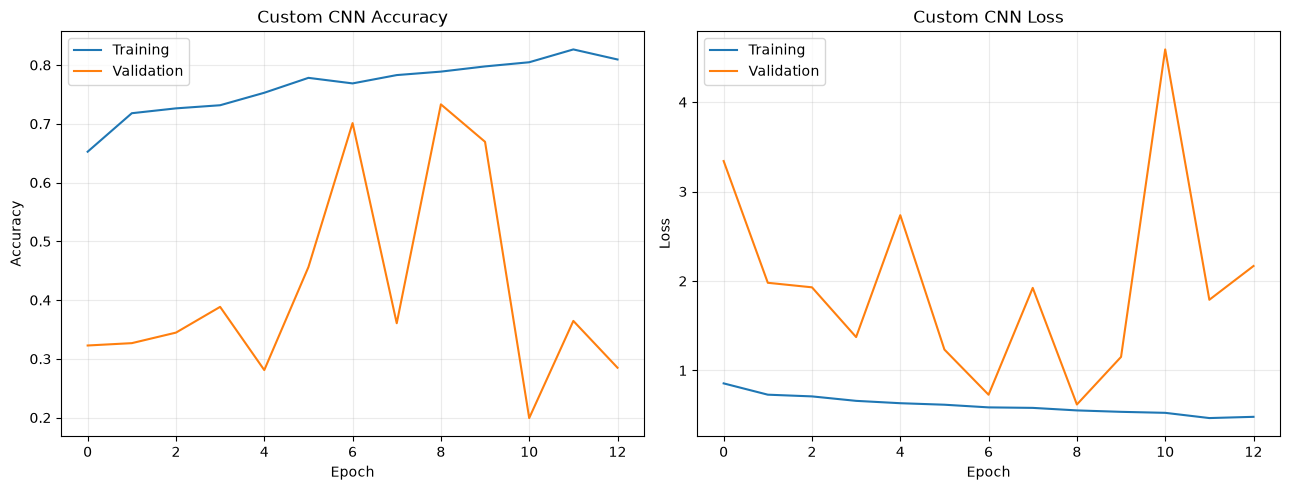

Saved: c:\Users\kalav\OneDrive\Desktop\Brain-Tumor-AI\reports\figures\custom_cnn_training_curves.png


In [9]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Custom CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Custom CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()

plot_path = FIGURES_DIR / "custom_cnn_training_curves.png"
fig.savefig(plot_path, dpi=130, bbox_inches="tight")
plt.show()

print("Saved:", plot_path)


In [10]:

best_epoch = int(history_df["val_loss"].idxmin())

results = {
    "model": "Custom CNN",
    "best_epoch": best_epoch,
    "best_validation_loss": float(history_df["val_loss"].min()),
    "best_validation_accuracy": float(history_df["val_accuracy"].max()),
    "epochs_completed": len(history_df),
    "parameters": int(model.count_params())
}

print(json.dumps(results, indent=2))

with open(
    REPORTS_DIR / "custom_cnn_results.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(results, file, indent=2)

print("\nResults saved to reports/custom_cnn_results.json")


{
  "model": "Custom CNN",
  "best_epoch": 9,
  "best_validation_loss": 0.6192483901977539,
  "best_validation_accuracy": 0.7330677509307861,
  "epochs_completed": 13,
  "parameters": 305380
}

Results saved to reports/custom_cnn_results.json
